# CNN para classificação de dígitos usando dataset MNIST

O objetivo deste trabalho é analisar como a representação de um dígito em uma imagem pode ser prevista utilizando redes neurais convolucionais (CNN). Para isso, será utilizada a base de dados **MNIST**, composta por imagens de dígitos manuscritos variando de 0 a 9.

Serão desenvolvidos dois modelos distintos:

- **Classificação Multiclasse**  
  Modelo responsável por identificar qual dígito (de 0 a 9) está presente na imagem.

- **Classificação Binária**  
  Modelo cujo objetivo é distinguir entre dois grupos de dígitos com base em suas formas visuais:
  
  - **Números curvos**: 0, 3, 6, 8, 9  
  - **Números retos**: 1, 2, 4, 5, 7

Esses modelos permitirão avaliar o desempenho da CNN em diferentes cenários de classificação, tanto com múltiplas classes quanto com uma separação binária baseada em características visuais dos dígitos.


In [1]:
#importing libs
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

Utilizaremos a camada de **MaxPooling**, pois ele captura características marcantes da imagem, o que é necessário para reconhecer picos e bordas, por exemplo.
- ***Classificação Multiclasse***: Camada de saída terá função de ativação **Softmax**, pois possibilita interpretação **probabilística**. Será usada a função de custo **Cross-entropy**, visto que verifica a diferença entre a distribuição de probabilidade atual e a esperada.
- ***Classificação Binária***: Camada de saída terá função de ativação **Sigmoid**, visto que permite retornar uma **probabilidade** com o uso de um **único** neurônio, simplificando o modelo. Será usada a **Binary Cross-entropy** como função de custo, o qual é uma Cross-entropy otimizada para classificação binária
<div style="text-align: center;">
    <table style="margin: auto;">
    <tr>
    <td><img src="images/sigmoid.png" width="300"/></td>
    <td><img src="images/softmax_grafic.png" width="300"/></td>
    <td><img src="images/softmax_function.png" width="300"/></td>
    </tr>
    <tr>
    <td style="text-align: center;">Sigmoid</td>
    <td style="text-align: center;">Softmax</td>
    <td style="text-align: center;">Sotmax Function</td>
    </tr>
    </table>
</div>

Serão encontrados os melhores hiperparâmetros através de uma ***RandomSearch***

**Hiperparâmetros**
- Número de camadas convolucionais:[2, 3];
- Filtros por camada: [32, 64, 128];
- Tamanho do kernel: [(3,3), (5,5)];
- Número de camadas densas(hidden layers): [1, 2];
- Unidades por camada densa(hidden layer): [64, 138, 256];
- Taxa de dropout: [0.2, 0.3];
- Taxa de aprendizado: [0.0001, 0.002, 0.05];
- Batch size: [32, 64, 128];
- Número de épocas: [10 ~ 30];

### Pré-processamento do MNIST

In [2]:
from tensorflow.keras.datasets import mnist

#load data
(x_train, y_train), (x_test, y_test) = mnist.load_data()

#Normaliza os pixels
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

#Convertendo para o shape esperado pelo Keras
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

In [3]:
def to_binary(y):
    curved_numbers = [0, 3, 6, 8, 9]
    return np.isin(y, curved_numbers).astype(int)

In [4]:
# binary classification
y_train_binary = to_binary(y_train)
y_test_binary = to_binary(y_test)

In [5]:
from tensorflow.keras.utils import to_categorical
y_train_categorical = to_categorical(y_train, 10) #One-hot encoding
y_test_categorical = to_categorical(y_test, 10)

In [11]:
param_grid = {
    "model__n_conv": [2, 3],
    "model__filters": [32, 64, 128],
    "model__kernel_size": [(3, 3), (5, 5)],
    "model__n_dense": [1, 2],
    "model__dense_units": [64, 128, 256],
    "model__dropout_rate": [0.2, 0.3],
    "model__learning_rate": [0.0001, 0.002, 0.05],
    "batch_size": [32, 64, 128]
}

In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam

def build_model_multiclass(n_conv=2, filters=32, kernel_size=(3,3), n_dense=1,
                dense_units=128, dropout_rate=0.3, learning_rate=0.001):

    model = Sequential()

    for i in range(n_conv):
        if i == 0:
            model.add(Conv2D(filters, kernel_size, activation='relu', padding='same', input_shape=(28, 28, 1)))
        else:
            model.add(Conv2D(filters, kernel_size, activation='relu', padding='same'))
        model.add(MaxPooling2D(pool_size=(2, 2)))

    model.add(Flatten())

    for _ in range(n_dense):
        model.add(Dense(dense_units, activation='relu'))
        model.add(Dropout(dropout_rate))


    model.add(Dense(10, activation='softmax'))
    loss = 'categorical_crossentropy'

    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss=loss,
                  metrics=['accuracy'])

    return model

In [13]:
def build_model_binary(n_conv=2, filters=32, kernel_size=(3,3), n_dense=1,
                dense_units=128, dropout_rate=0.3, learning_rate=0.001):

    model = Sequential()

    for i in range(n_conv):
        if i == 0:
            model.add(Conv2D(filters, kernel_size, activation='relu', padding='same', input_shape=(28, 28, 1)))
        else:
            model.add(Conv2D(filters, kernel_size, activation='relu', padding='same'))
        model.add(MaxPooling2D(pool_size=(2, 2)))

    model.add(Flatten())

    for _ in range(n_dense):
        model.add(Dense(dense_units, activation='relu'))
        model.add(Dropout(dropout_rate))


    model.add(Dense(1, activation='sigmoid'))
    loss = 'binary_crossentropy'

    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss=loss,
                  metrics=['accuracy'])

    return model

### Classificação Multiclasse
Prever o número representado pela imagem fornecida

In [27]:
from sklearn.metrics import accuracy_score

In [57]:
import itertools
import random
def random_search(grid, x, y, type='multiclass', n_samples=20):
    all_combinations = list(itertools.product(
        grid['model__n_conv'],
        grid['model__filters'],
        grid['model__kernel_size'],
        grid['model__n_dense'],
        grid['model__dense_units'],
        grid['model__dropout_rate'],
        grid['model__learning_rate'],
        grid['batch_size']
    ))
    samples = random.sample(all_combinations, n_samples)
    metrics = []
    X_train, X_val, Y_train, Y_val = train_test_split(x, y, stratify=y)
    for combination in samples:
        if type =='multiclass':
            n_conv, filters, kernel_size, n_dense,  dense_units, dropout_rate, learning_rate, batch_size = combination
            print(combination)
            model = build_model_multiclass(n_conv,filters, kernel_size, n_dense, dense_units, dropout_rate,
                                           learning_rate)
            model.fit(X_train, Y_train, batch_size=batch_size, epochs=10)
            y_pred = model.predict(X_val)
            y_val = np.argmax(Y_val, axis=1)
            y_pred_classes = np.argmax(y_pred, axis=1)
            acc = accuracy_score(y_val, y_pred_classes)
            metrics.append({
                'n_conv': n_conv,
                'filters': filters,
                'kernel_size': kernel_size,
                'n_dense': n_dense,
                'dense_units': dense_units,
                'dropout_rate': dropout_rate,
                'learning_rate': learning_rate,
                'batch_size': batch_size,
                'acc': acc
            })
        else:
            n_conv, filters, kernel_size, n_dense,  dense_units, dropout_rate, learning_rate, batch_size = combination
            model = build_model_binary(n_conv,filters, kernel_size, n_dense, dense_units, dropout_rate,
                                           learning_rate)
            print(combination)
            model.fit(X_train, Y_train, batch_size=batch_size, epochs=10)
            y_pred_prob = model.predict(X_val)
            y_pred_class = (y_pred_prob > 0.5).astype(int)  # Converte para 0 ou 1
            acc = accuracy_score(Y_val, y_pred_class)
            metrics.append({
                'n_conv': n_conv,
                'filters': filters,
                'kernel_size': kernel_size,
                'n_dense': n_dense,
                'dense_units': dense_units,
                'dropout_rate': dropout_rate,
                'learning_rate': learning_rate,
                'batch_size': batch_size,
                'acc': acc
            })
    return metrics

Foi fixado 10 epócas, pois percebeu-se que vários modelos conseguia atingir um bom desempenho com 10 ou menos epócas. Em alguns casos, seria interessante aplicar o Early Stopping.

In [30]:
metrics = random_search(param_grid, x_train, y_train_categorical, n_samples=20)

(3, 64, (5, 5), 2, 64, 0.2, 0.002, 32)
Epoch 1/10


c:\Users\Usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1407/1407 ━━━━━━━━━━━━━━━━━━━━ 23s 15ms/step - accuracy: 0.8193 - loss: 0.5364
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 26s 18ms/step - accuracy: 0.9791 - loss: 0.0747
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 26s 18ms/step - accuracy: 0.9838 - loss: 0.0589
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 26s 18ms/step - accuracy: 0.9893 - loss: 0.0409
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 26s 18ms/step - accuracy: 0.9901 - loss: 0.0366
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 26s 18ms/step - accuracy: 0.9912 - loss: 0.0351
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 26s 19ms/step - accuracy: 0.9918 - loss: 0.0281
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 27s 19ms/step - accuracy: 0.9925 - loss: 0.0295
Epoch 9/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 27s 19ms/step - accuracy: 0.9938 - loss: 0.0246
Epoch 10/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 26s 19ms/step - accuracy: 0.9921 - loss: 0.0302
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step
(3, 128, (5, 5), 2, 64, 0.2, 0.002, 128)
Epoch 1/10


c:\Users\Usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


352/352 ━━━━━━━━━━━━━━━━━━━━ 79s 222ms/step - accuracy: 0.7440 - loss: 0.7334
Epoch 2/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 78s 222ms/step - accuracy: 0.9780 - loss: 0.0803
Epoch 3/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 81s 231ms/step - accuracy: 0.9861 - loss: 0.0542
Epoch 4/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 79s 223ms/step - accuracy: 0.9891 - loss: 0.0400
Epoch 5/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 79s 224ms/step - accuracy: 0.9902 - loss: 0.0342
Epoch 6/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 79s 224ms/step - accuracy: 0.9924 - loss: 0.0283
Epoch 7/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 77s 218ms/step - accuracy: 0.9940 - loss: 0.0224
Epoch 8/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 78s 220ms/step - accuracy: 0.9933 - loss: 0.0242
Epoch 9/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 77s 218ms/step - accuracy: 0.9951 - loss: 0.0177
Epoch 10/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 75s 213ms/step - accuracy: 0.9946 - loss: 0.0211
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step
(2, 128, (5, 5), 1, 64, 0.3, 0.002, 64)
Epoch 1/10


...

352/352 ━━━━━━━━━━━━━━━━━━━━ 77s 216ms/step - accuracy: 0.1030 - loss: 204.0884
Epoch 2/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 75s 214ms/step - accuracy: 0.1070 - loss: 2.3044
Epoch 3/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 76s 215ms/step - accuracy: 0.1070 - loss: 2.3041
Epoch 4/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 76s 215ms/step - accuracy: 0.1078 - loss: 2.3035
Epoch 5/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 75s 214ms/step - accuracy: 0.1064 - loss: 2.3046
Epoch 6/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 75s 212ms/step - accuracy: 0.1094 - loss: 2.3046
Epoch 7/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 74s 210ms/step - accuracy: 0.1079 - loss: 2.3043
Epoch 8/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 73s 207ms/step - accuracy: 0.1043 - loss: 2.3050
Epoch 9/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 73s 206ms/step - accuracy: 0.1094 - loss: 2.3043
Epoch 10/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 73s 206ms/step - accuracy: 0.1048 - loss: 2.3042
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step
(3, 32, (3, 3), 2, 64, 0.2, 0.002, 32)
Epoch 1/10


c:\Users\Usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8014 - loss: 0.5878
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9730 - loss: 0.0962
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9799 - loss: 0.0705
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9859 - loss: 0.0515
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9870 - loss: 0.0447
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9884 - loss: 0.0423
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9893 - loss: 0.0381
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9895 - loss: 0.0339
Epoch 9/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9904 - loss: 0.0335
Epoch 10/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9914 - loss: 0.0291
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
(2, 64, (5, 5), 2, 256, 0.3, 0.05, 128)
Epoch 1/10


c:\Users\Usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 59ms/step - accuracy: 0.1033 - loss: 18.1025
Epoch 2/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 21s 60ms/step - accuracy: 0.1075 - loss: 2.3041
Epoch 3/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 21s 60ms/step - accuracy: 0.1083 - loss: 2.3041
Epoch 4/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 64ms/step - accuracy: 0.1109 - loss: 2.3045
Epoch 5/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 63ms/step - accuracy: 0.1055 - loss: 2.3041
Epoch 6/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 21s 61ms/step - accuracy: 0.1072 - loss: 2.3044
Epoch 7/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 21s 60ms/step - accuracy: 0.1059 - loss: 2.3038
Epoch 8/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 63ms/step - accuracy: 0.1070 - loss: 2.3049
Epoch 9/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 62ms/step - accuracy: 0.1074 - loss: 2.3047
Epoch 10/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 64ms/step - accuracy: 0.1040 - loss: 2.3048
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step


In [31]:
import pandas as pd

results = pd.DataFrame(metrics)

In [32]:
results.head()

,n_conv,filters,kernel_size,n_dense,dense_units,dropout_rate,learning_rate,batch_size,acc
0,3,64,"(5, 5)",2,64,0.2,0.002,32,0.990200
1,3,128,"(5, 5)",2,64,0.2,0.002,128,0.991733
2,2,128,"(5, 5)",1,64,0.3,0.002,64,0.990467
3,3,128,"(3, 3)",1,128,0.2,0.050,32,0.822400
4,2,64,"(5, 5)",1,256,0.2,0.002,32,0.988667


In [39]:
# function for plot heatmap
def plot_heatmap(results, x, y, score_name='acc', annot=True, fmt=".3f", cmap="viridis"):
  if x not in results.columns or y not in results.columns:
      raise ValueError(f"Columns '{x}' and '{y}' must be in the results DataFrame.")
  pivot_table = results.pivot_table(index=y, columns=x, values=score_name)
  plt.figure(figsize=(10, 6))
  sns.heatmap(pivot_table, annot=annot, fmt=fmt, cmap=cmap)
  plt.title(f"Heatmap of {score_name} by {x} and {y}")
  plt.xlabel(x)
  plt.ylabel(y)
  plt.show()

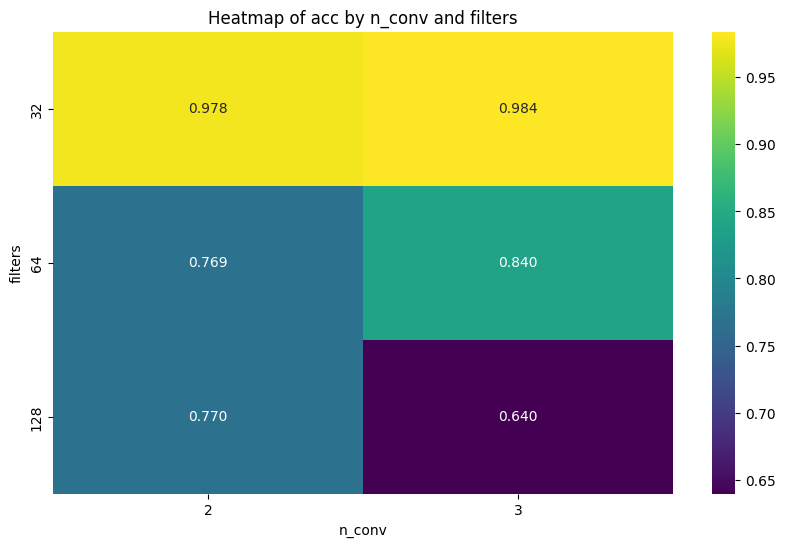

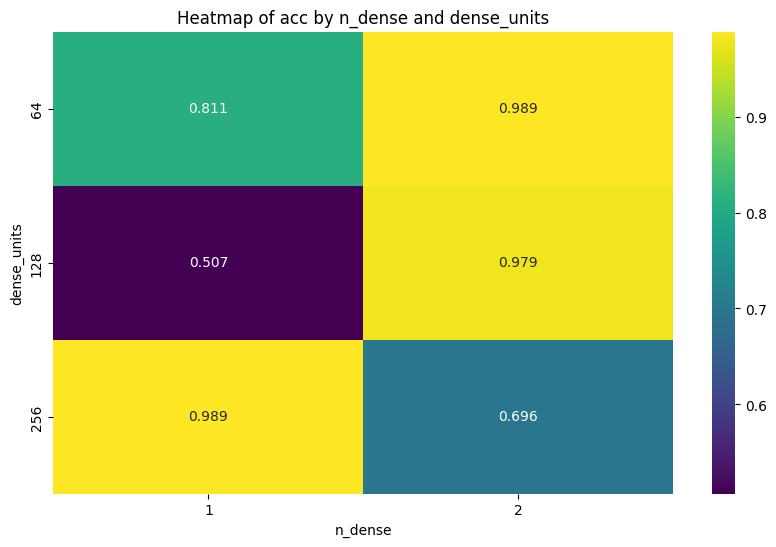

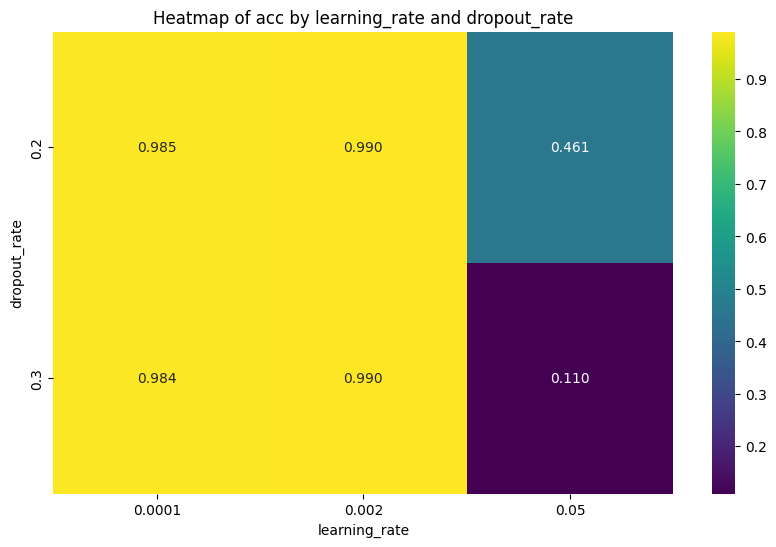

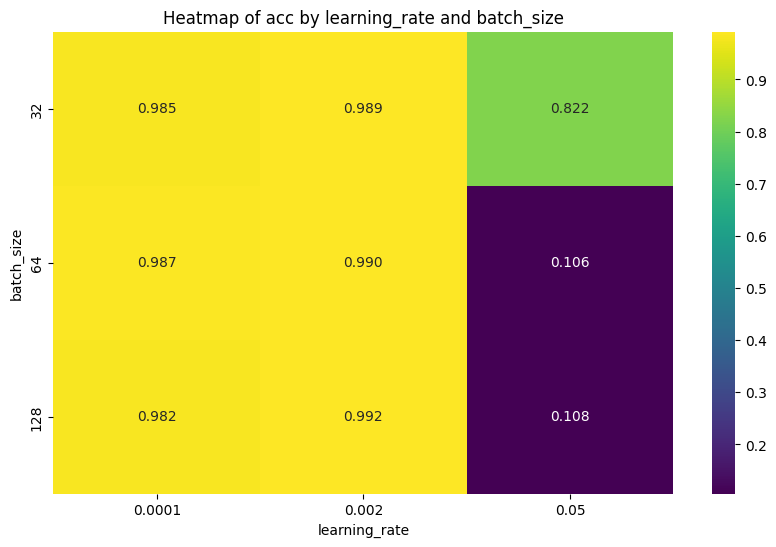

In [40]:
#Análise da influência dos hiperparâmetros
plot_heatmap(results, 'n_conv', 'filters')
plot_heatmap(results, 'n_dense','dense_units')
plot_heatmap(results, 'learning_rate', 'dropout_rate')
plot_heatmap(results, 'learning_rate', 'batch_size')

Analisando os mapas de calor, percebemos alguns fenômenos:
- O uso de uma quantidade grande de filtros por camada caiu o desempenho da CNN
- O aumento da quantidade de camadas de convolução não afetou significativamente a previsão, mas a quantidade de filtros sim
- Ao aumentar a quantidade de camadas densa, o desempenho cresce quando reduzimos a quantidade de neurônios por camada
- Ao reduzir a quantidade de camadas densa, o desempenho sobe somente quando aumenta a quantidade de neurônios por camada
- Taxa de aprendizado muito alta piorou significativamente o modelo
- Dropout não proporciou melhora o suficiente ao modelo, mas a principal determinante foi a taxa de aprendizado
- O único cenário que a taxa de aprendizado alta forneceu um bom desempenho foi com tamanho de lote pequeno

In [43]:
better_params = results[results['acc'] == results['acc'].max()]
better_params

,n_conv,filters,kernel_size,n_dense,dense_units,dropout_rate,learning_rate,batch_size,acc
1,3,128,"(5, 5)",2,64,0.2,0.002,128,0.991733


In [47]:
n_conv, filters, kernel_size, n_dense, dense_units, dropout_rate, learning_rate, batch_size, acc = better_params.iloc[0].values
model_multiclass = build_model_multiclass(n_conv, filters, kernel_size, n_dense, dense_units,
                                          dropout_rate, learning_rate)
model_multiclass.fit(x_train, y_train_categorical, batch_size=better_params['batch_size'].iloc[0], epochs=10)

c:\Users\Usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 104s 219ms/step - accuracy: 0.7960 - loss: 0.5972
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 109s 232ms/step - accuracy: 0.9820 - loss: 0.0673
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 103s 219ms/step - accuracy: 0.9888 - loss: 0.0426
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 104s 221ms/step - accuracy: 0.9910 - loss: 0.0351
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 104s 222ms/step - accuracy: 0.9927 - loss: 0.0289
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 102s 217ms/step - accuracy: 0.9935 - loss: 0.0235
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 102s 217ms/step - accuracy: 0.9946 - loss: 0.0197
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 102s 217ms/step - accuracy: 0.9950 - loss: 0.0182
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 104s 222ms/step - accuracy: 0.9963 - loss: 0.0134
Epoch 10/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 101s 215ms/step - accuracy: 0.9961 - loss: 0.0153


In [48]:
y_pred_categorical = model_multiclass.predict(x_test)
y_pred_labels = np.argmax(y_pred_categorical, axis=1)
y_true_labels = np.argmax(y_test_categorical, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step


In [49]:
def plot_confusion_matrix(y_true, y_pred, labels):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predito')
    plt.ylabel('Real')
    plt.title('Matriz de Confusão')
    plt.show()

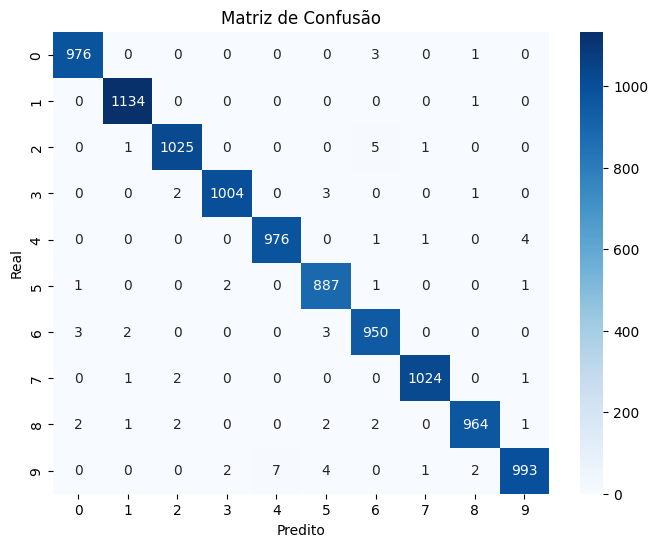

In [50]:
labels = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
# result
plot_confusion_matrix(y_true_labels, y_pred_labels, labels)

In [51]:
print(accuracy_score(y_true_labels, y_pred_labels))

0.9933


In [54]:
#save model_multiclass
model_multiclass.save("models/multiclass.keras")

A CNN obteve ótimos resultados, com uma acurácia de **99,3%**. O número que houve maior taxa de previsões erradas foi o 5, onde o modelo confundiu bastante com números de forma curva como 9, 6 e 3. O número com a menor quantidade de previsões erradas foi o 1, visto que tal número tem pouca similaridade com outros dígitos.

### Classificação Binária
Prever se a imagem representa um número curvo ou reto.
- Classe positiva: número curvo
- Classe negativa: número reto

In [58]:
metrics = random_search(param_grid, x_train, y_train_binary, type='binary', n_samples=20)

(3, 64, (5, 5), 2, 64, 0.3, 0.002, 128)
Epoch 1/10


c:\Users\Usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 58ms/step - accuracy: 0.8694 - loss: 0.2639
Epoch 2/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 64ms/step - accuracy: 0.9901 - loss: 0.0325
Epoch 3/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 23s 65ms/step - accuracy: 0.9936 - loss: 0.0212
Epoch 4/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 23s 64ms/step - accuracy: 0.9952 - loss: 0.0134
Epoch 5/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 23s 66ms/step - accuracy: 0.9957 - loss: 0.0132
Epoch 6/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 23s 65ms/step - accuracy: 0.9973 - loss: 0.0090
Epoch 7/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 23s 65ms/step - accuracy: 0.9972 - loss: 0.0099
Epoch 8/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 64ms/step - accuracy: 0.9983 - loss: 0.0053
Epoch 9/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 64ms/step - accuracy: 0.9977 - loss: 0.0061
Epoch 10/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 63ms/step - accuracy: 0.9985 - loss: 0.0046
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step
(3, 128, (3, 3), 1, 64, 0.3, 0.002, 64)
Epoch 1/10


c:\Users\Usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


704/704 ━━━━━━━━━━━━━━━━━━━━ 42s 58ms/step - accuracy: 0.9049 - loss: 0.2044
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 40s 57ms/step - accuracy: 0.9882 - loss: 0.0361
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 40s 57ms/step - accuracy: 0.9922 - loss: 0.0215
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 40s 57ms/step - accuracy: 0.9949 - loss: 0.0160
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 41s 59ms/step - accuracy: 0.9953 - loss: 0.0143
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 41s 58ms/step - accuracy: 0.9966 - loss: 0.0110
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 40s 57ms/step - accuracy: 0.9972 - loss: 0.0096
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 41s 58ms/step - accuracy: 0.9978 - loss: 0.0073
Epoch 9/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 42s 59ms/step - accuracy: 0.9971 - loss: 0.0086
Epoch 10/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 40s 56ms/step - accuracy: 0.9972 - loss: 0.0079
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step
(2, 128, (3, 3), 1, 128, 0.2, 0.002, 64)
Epoch 1/10


...

1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.7968 - loss: 0.4311
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9610 - loss: 0.1091
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9741 - loss: 0.0761
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.9792 - loss: 0.0620
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9822 - loss: 0.0528
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9849 - loss: 0.0460
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9868 - loss: 0.0382
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9871 - loss: 0.0371
Epoch 9/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9889 - loss: 0.0336
Epoch 10/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9900 - loss: 0.0308
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
(2, 128, (5, 5), 1, 256, 0.3, 0.002, 32)
Epoch 1/10


c:\Users\Usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1407/1407 ━━━━━━━━━━━━━━━━━━━━ 84s 59ms/step - accuracy: 0.9189 - loss: 0.1794
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 85s 60ms/step - accuracy: 0.9899 - loss: 0.0312
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 82s 58ms/step - accuracy: 0.9917 - loss: 0.0233
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 83s 59ms/step - accuracy: 0.9931 - loss: 0.0174
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 81s 58ms/step - accuracy: 0.9948 - loss: 0.0140
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 80s 57ms/step - accuracy: 0.9959 - loss: 0.0126
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 78s 55ms/step - accuracy: 0.9956 - loss: 0.0148
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 77s 55ms/step - accuracy: 0.9968 - loss: 0.0112
Epoch 9/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 77s 55ms/step - accuracy: 0.9981 - loss: 0.0070
Epoch 10/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 77s 55ms/step - accuracy: 0.9974 - loss: 0.0076
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step
(2, 32, (3, 3), 1, 256, 0.3, 0.05, 32)
Epoch 1/10


c:\Users\Usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.7767 - loss: 0.6141
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8553 - loss: 0.3411
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8562 - loss: 0.3358
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8550 - loss: 0.3383
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8579 - loss: 0.3368
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8598 - loss: 0.3335
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8624 - loss: 0.3334
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8612 - loss: 0.3309
Epoch 9/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8612 - loss: 0.3296
Epoch 10/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8693 - loss: 0.3240
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [59]:
results = pd.DataFrame(metrics)
results.head()

,n_conv,filters,kernel_size,n_dense,dense_units,dropout_rate,learning_rate,batch_size,acc
0,3,64,"(5, 5)",2,64,0.3,0.002,128,0.993733
1,3,128,"(3, 3)",1,64,0.3,0.002,64,0.993533
2,2,128,"(3, 3)",1,128,0.2,0.002,64,0.993800
3,2,64,"(3, 3)",1,128,0.2,0.002,64,0.993533
4,3,64,"(5, 5)",2,64,0.3,0.002,32,0.993400


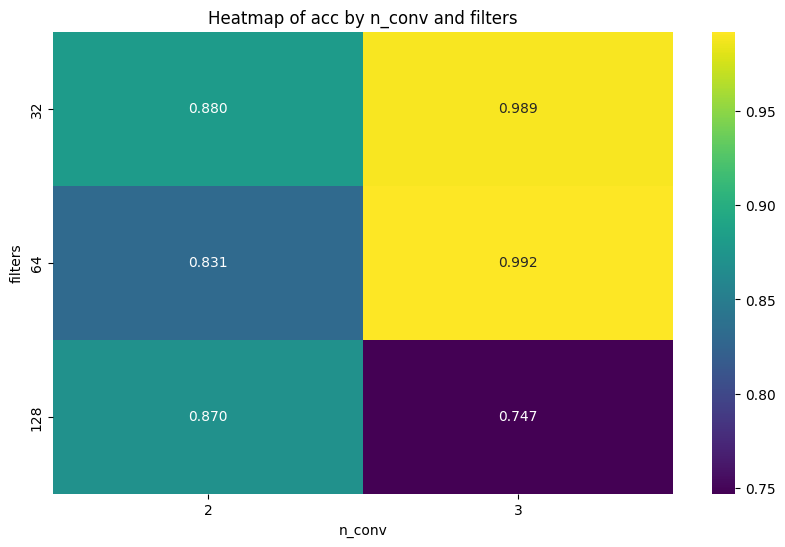

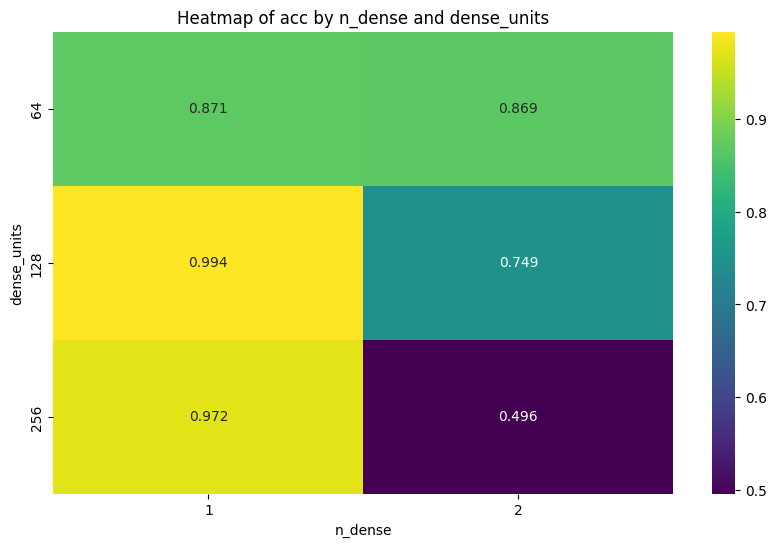

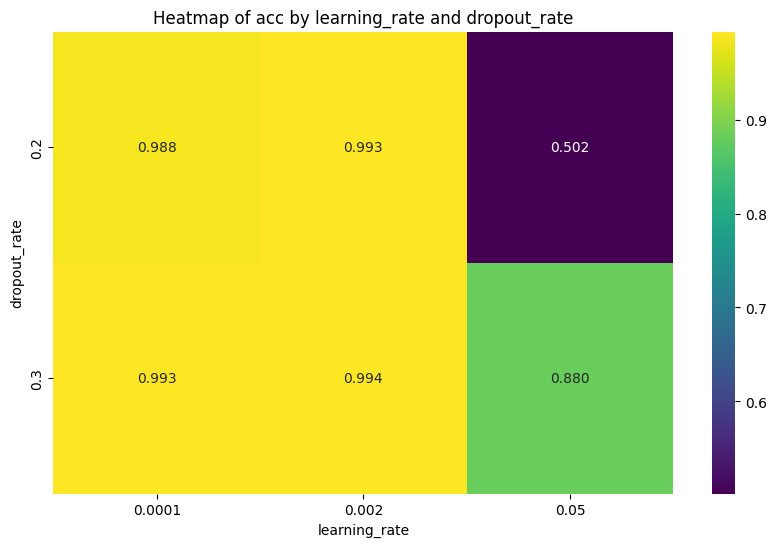

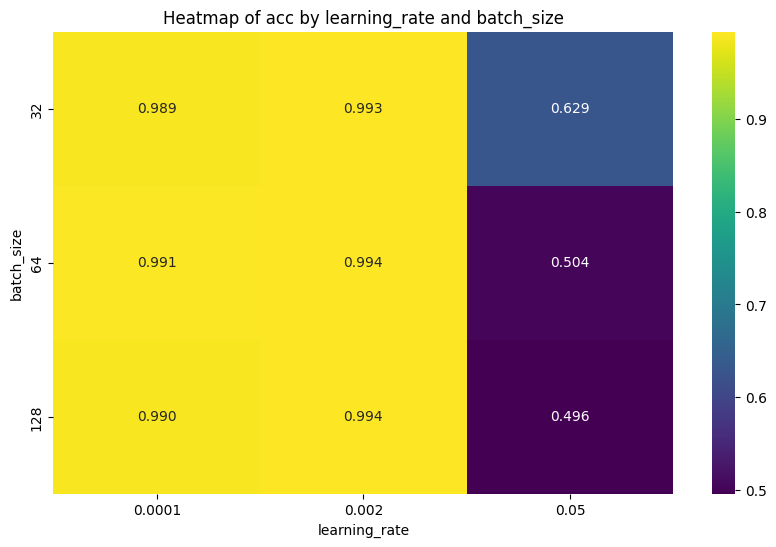

In [60]:
#Análise da influência dos hiperparâmetros
plot_heatmap(results, 'n_conv', 'filters')
plot_heatmap(results, 'n_dense','dense_units')
plot_heatmap(results, 'learning_rate', 'dropout_rate')
plot_heatmap(results, 'learning_rate', 'batch_size')

Analisando os mapas de calor, percebe-se os seguintes fenômenos:
- Taxas de aprendizado menores implicaram em modelos mais robustos
- A taxa de dropout melhorou o desempenho ao usar altas taxas de aprendizado
- Menor tamanho de lote ajuda quando há altas taxas de aprendizado
- Aumentar a quantidade de camadas densas piorou o modelo. Novamente, ao aumentar a quantidade de camadas, para possuir um bom desempenho, tinha que diminuir o número de neurônios por camada. O contrário também ocorreu.
- Ao aumentar a quantidade de camadas convolucionais, houve melhor desempenho com números menores de filtros.

In [61]:
better_params = results[results['acc'] == results['acc'].max()]
better_params

,n_conv,filters,kernel_size,n_dense,dense_units,dropout_rate,learning_rate,batch_size,acc
13,2,64,"(5, 5)",2,128,0.3,0.002,128,0.994533


In [62]:
n_conv, filters, kernel_size, n_dense, dense_units, dropout_rate, learning_rate, batch_size, acc = better_params.iloc[0].values
model_binary = build_model_binary(n_conv, filters, kernel_size, n_dense, dense_units,
                                          dropout_rate, learning_rate)
model_binary.fit(x_train, y_train_binary, batch_size=better_params['batch_size'].iloc[0], epochs=10)

c:\Users\Usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 25s 51ms/step - accuracy: 0.9126 - loss: 0.1843
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 27s 58ms/step - accuracy: 0.9906 - loss: 0.0287
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 27s 58ms/step - accuracy: 0.9926 - loss: 0.0203
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 27s 58ms/step - accuracy: 0.9951 - loss: 0.0150
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 27s 58ms/step - accuracy: 0.9953 - loss: 0.0140
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 27s 57ms/step - accuracy: 0.9968 - loss: 0.0094
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 28s 60ms/step - accuracy: 0.9973 - loss: 0.0089
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 27s 58ms/step - accuracy: 0.9973 - loss: 0.0076
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 27s 57ms/step - accuracy: 0.9973 - loss: 0.0091
Epoch 10/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 28s 60ms/step - accuracy: 0.9985 - loss: 0.0044


In [63]:
y_pred_prob_binary = model_binary.predict(x_test)
y_pred_labels = (y_pred_prob_binary > 0.5).astype(int)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step


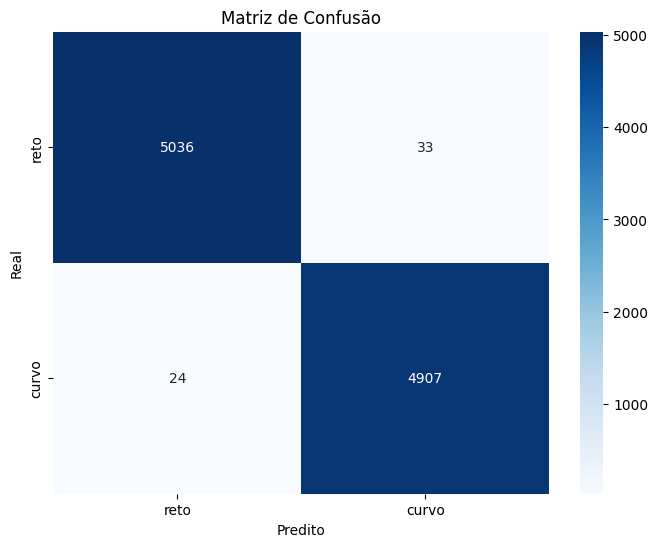

In [64]:
labels = ["reto", "curvo"]
# result
plot_confusion_matrix(y_test_binary, y_pred_labels, labels)

In [65]:
from sklearn.metrics import precision_score, recall_score, f1_score
acc = accuracy_score(y_test_binary, y_pred_labels)
prec = precision_score(y_test_binary, y_pred_labels)
rec = recall_score(y_test_binary, y_pred_labels)
f1 = f1_score(y_test_binary, y_pred_labels)

In [66]:
print(f"Acurácia: {acc:.4f}")
print(f"Precisão: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-Score: {f1:.4f}")

Acurácia: 0.9943
Precisão: 0.9933
Recall: 0.9951
F1-Score: 0.9942


In [67]:
model_binary.save("models/binary.keras")

O modelo de classificação binária obteve ótimos resultados no conjunto de teste. O modelo sofre mais em acertar números curvos do que retos. Tanto no binário, quanto em multiclasse, taxa de aprendizado alto implicou na piora no modelo. Observou-se que em ambos os cenários, a early stopping poderia ser utilizada, visto que depois de algumas épocas o desempenho não crescia significativamente. Praticamente, em ambas as situações ocorreram os mesmos fenômenos quanto a escolha dos hiperparâmetros